# Reconnaissance des émotions faciales (FER-2013) : CNN vs Vision Transformer léger, pooling attentionnel et analyse d'erreurs

**Objectif.** Répondre proprement à la question : *« Le Transformer est-il meilleur que le CNN, et pourquoi ? »*

Ce notebook apporte :

1. **Protocole rigoureux** : le jeu `val` de FER-2013 (7 178 images) est coupé en deux moitiés stratifiées : *sélection du meilleur checkpoint* et *test final* (jamais utilisé pour choisir quoi que ce soit). Chaque expérience est répétée avec **3 graines** (moyenne ± écart-type).
2. **Comparaison contrôlée** : même résolution, mêmes données, même nombre d'époques, même optimiseur pour tous les modèles.
3. **Ablations** : effet du **préentraînement ImageNet** (MobileViT depuis zéro vs préentraîné) et effet de la **tête de pooling attentionnel** (inspirée de Xue et al.) vs pooling moyen.
4. **Efficacité** : nombre de paramètres et latence mesurée correctement (CPU, batch de 1, avec échauffement).
5. **Analyse d'erreurs** : matrices de confusion, F1 par classe, exemples mal classés, Grad-CAM (CNN) et cartes d'attention (tête attentionnelle).

| Nom | Description |
|---|---|
| `cnn_scratch` | CNN type Modi et al., depuis zéro |
| `mobilevit_scratch` | MobileViT-XXS, poids aléatoires |
| `mobilevit_pretrained` | MobileViT-XXS préentraîné ImageNet, pooling moyen (tête standard) |
| `mobilevit_attnpool` | MobileViT-XXS préentraîné + **pooling attentionnel** |

**Utilisation.** Exécutez les cellules dans l'ordre. Mettez `QUICK = True` dans la cellule de configuration pour un test rapide (1 graine, 2 époques) avant de lancer la vraie expérience. Les résultats de chaque exécution sont sauvegardés dans `results/` : si Colab plante, relancez simplement la cellule d'entraînement, elle reprend là où elle s'est arrêtée.

In [ ]:
!pip install -q timm

## 1. Configuration et reproductibilité

In [ ]:
import os, time, json, copy, random, zipfile, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# ====================== PARAMÈTRES À MODIFIER ======================
QUICK = False          # True = test rapide (1 graine, 2 époques)
IMG_SIZE = 96          # même résolution pour TOUS les modèles (96 ou 128)
EPOCHS = 20            # même nombre d'époques pour TOUS les modèles
BATCH_SIZE = 128
SEEDS = [0, 1, 2]
NUM_WORKERS = 2
DATA_DIR = "."   # dossier contenant train/ et val/ (ou test/)
# ===================================================================

if QUICK:
    EPOCHS, SEEDS = 2, [0]

RESULTS = Path("results_quick" if QUICK else "results")
(RESULTS / "ckpt").mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"     # précision mixte pour accélérer sur GPU
print(f"Device : {device} | AMP : {USE_AMP} | résolution : {IMG_SIZE} | époques : {EPOCHS} | graines : {SEEDS}")
print(f"torch {torch.__version__} | timm {timm.__version__}")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False

Device : cuda | AMP : True | résolution : 96 | époques : 20 | graines : [0, 1, 2]
torch 2.14.1+cu130 | timm 1.0.31


## 2. Données et découpage val / test

On utilise le jeu `val` fourni (7 178 images, très probablement PublicTest + PrivateTest de FER-2013) et on le coupe en deux moitiés **stratifiées** avec une graine fixe (`random_state=42`) :
- `val_sel` : sert uniquement à **choisir la meilleure époque** ;
- `test` : sert uniquement au **résultat final**.

Les images FER-2013 sont en niveaux de gris : on les convertit en 3 canaux identiques pour pouvoir utiliser les poids préentraînés ImageNet. Les images 48×48 sont agrandies à `IMG_SIZE` : cela n'ajoute pas d'information, mais permet au MobileViT (stride total de 32) d'avoir une carte de caractéristiques utilisable.

In [ ]:
def find_root():
    for p in [Path(DATA_DIR), Path("."), Path("dataset")]:
        if (p / "train").is_dir() and ((p / "val").is_dir() or (p / "test").is_dir()):
            return p
    return None

root = find_root()
if root is None and Path("dataset.zip").exists():
    with zipfile.ZipFile("dataset.zip") as z:
        z.extractall(DATA_DIR)
    root = find_root()
if root is None:
    raise FileNotFoundError(
        "Dataset introuvable. Placez dataset.zip à côté du notebook, ou un dossier contenant "
        "train/ et val/ (ou test/), un sous-dossier par émotion (FER-2013).")

val_name = "val" if (root / "val").is_dir() else "test"
print("Racine du dataset :", root, "| dossier d'évaluation :", val_name)

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
S = IMG_SIZE

train_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((S, S)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((S, S)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = datasets.ImageFolder(root / "train", transform=train_tf)
eval_full = datasets.ImageFolder(root / val_name, transform=eval_tf)
class_names = train_ds.classes
NUM_CLASSES = len(class_names)
assert eval_full.classes == class_names, "Les classes de train et val ne correspondent pas"

targets_full = np.array(eval_full.targets)
idx_sel, idx_test = train_test_split(
    np.arange(len(targets_full)), test_size=0.5, stratify=targets_full, random_state=42)
val_ds = Subset(eval_full, idx_sel)
test_ds = Subset(eval_full, idx_test)

print(f"Classes : {class_names}")
print(f"Train : {len(train_ds)} | val_sel : {len(val_ds)} | test : {len(test_ds)}")

Racine du dataset : . | dossier d'évaluation : test
Classes : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Train : 28709 | val_sel : 3589 | test : 3589


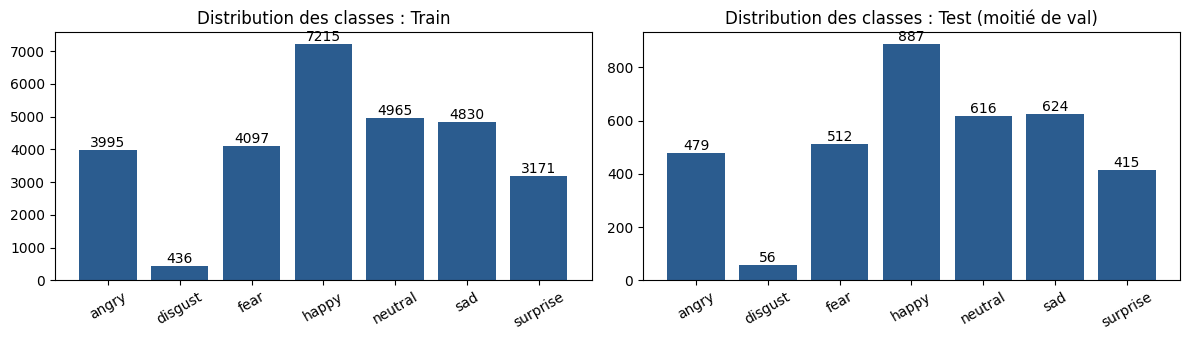

In [ ]:
# Distribution des classes (déséquilibre) : à commenter dans l'analyse
train_counts = np.bincount(train_ds.targets, minlength=NUM_CLASSES)
test_counts = np.bincount(targets_full[idx_test], minlength=NUM_CLASSES)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, c, t in zip(ax, [train_counts, test_counts], ["Train", "Test (moitié de val)"]):
    bars = a.bar(class_names, c, color="#2b5c8f")
    a.bar_label(bars)
    a.set_title(f"Distribution des classes : {t}")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(RESULTS / "class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Modèles

- **`EmotionCNN`** : le CNN du premier notebook (4 blocs Conv-BN-ReLU, pooling moyen global). Les ReLU ne sont plus *in-place* pour que Grad-CAM fonctionne.
- **MobileViT-XXS** (`timm`) : hybride convolution + blocs Transformer.
- **`AttnPoolHead`** : pooling attentionnel. Au lieu de moyenner toutes les positions de la carte de caractéristiques, on apprend un **score par position** (petit réseau 1×1), on le normalise par softmax, et on fait la moyenne **pondérée**. Le modèle peut ainsi se concentrer sur les régions utiles (bouche, yeux, sourcils) et ignorer le fond. C'est une version simple de l'idée de Xue et al. (qui sélectionnent les tokens les plus pertinents selon l'attention) : **c'est une approximation inspirée de l'article, pas une reproduction à l'identique**.

In [ ]:
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        def block(cin, cout, pool=True):
            layers = [nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=False)]
            if pool:
                layers.append(nn.MaxPool2d(2, 2))
            return layers
        self.features = nn.Sequential(
            *block(3, 32), *block(32, 64), *block(64, 128),        # indices 0..11
            *block(128, 256, pool=False),                          # indices 12..14 (conv, bn, relu)
            nn.AdaptiveAvgPool2d((1, 1)),                          # index 15
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.5), nn.Linear(256, 128), nn.ReLU(inplace=True),
            nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


class AttnPoolHead(nn.Module):
    # Pooling attentionnel sur une carte de caractéristiques (B, C, H, W)
    def __init__(self, c, num_classes, p=0.2):
        super().__init__()
        self.score = nn.Sequential(nn.Conv2d(c, max(c // 4, 8), 1), nn.Tanh(), nn.Conv2d(max(c // 4, 8), 1, 1))
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(c, num_classes)

    def forward(self, f, return_attn=False):
        B, C, H, W = f.shape
        a = self.score(f).flatten(2).softmax(-1)          # (B, 1, H*W) : poids d'attention
        x = (f.flatten(2) * a).sum(-1)                    # (B, C) : moyenne pondérée
        out = self.fc(self.drop(x))
        return (out, a.view(B, H, W)) if return_attn else out


class MobileViTAttn(nn.Module):
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model("mobilevit_xxs", pretrained=pretrained, num_classes=0, global_pool="")
        self.head = AttnPoolHead(self.backbone.num_features, num_classes)

    def forward(self, x, return_attn=False):
        f = self.backbone.forward_features(x)
        assert f.ndim == 4, f"Carte de caractéristiques attendue (B,C,H,W), obtenu {tuple(f.shape)}"
        return self.head(f, return_attn)


# nom -> (pretrained par défaut, learning rate)
EXPERIMENTS = {
    "cnn_scratch":          dict(pretrained=False, lr=1e-3),
    "mobilevit_scratch":    dict(pretrained=False, lr=1e-3),
    "mobilevit_pretrained": dict(pretrained=True,  lr=3e-4),
    "mobilevit_attnpool":   dict(pretrained=True,  lr=3e-4),
}

def build_model(name, pretrained=None):
    pre = EXPERIMENTS[name]["pretrained"] if pretrained is None else pretrained
    if name == "cnn_scratch":
        return EmotionCNN(NUM_CLASSES)
    if name in ("mobilevit_scratch", "mobilevit_pretrained"):
        return timm.create_model("mobilevit_xxs", pretrained=pre, num_classes=NUM_CLASSES)
    if name == "mobilevit_attnpool":
        return MobileViTAttn(NUM_CLASSES, pretrained=pre)
    raise ValueError(name)

# Vérification rapide des formes de sortie
for n in EXPERIMENTS:
    m = build_model(n).eval()
    with torch.no_grad():
        y = m(torch.randn(2, 3, S, S))
    print(f"{n:22s} sortie {tuple(y.shape)} | {sum(p.numel() for p in m.parameters())/1e6:.2f} M paramètres")

cnn_scratch            sortie (2, 7) | 0.42 M paramètres
mobilevit_scratch      sortie (2, 7) | 0.95 M paramètres


model.safetensors: reconstructing file:   0%|          |  0.00B / 5.14MB            

model.safetensors: downloading bytes:           |  0.00B            

mobilevit_pretrained   sortie (2, 7) | 0.95 M paramètres
mobilevit_attnpool     sortie (2, 7) | 0.98 M paramètres


## 4. Entraînement et évaluation (3 graines × 4 modèles)

Protocole identique pour tous : AdamW (weight decay 1e-4), scheduler cosinus, même nombre d'époques, même augmentation. Seul le learning rate diffère entre modèles depuis zéro (1e-3) et préentraînés (3e-4), comme dans les notebooks d'avant.

À chaque époque on mesure la précision sur `val_sel`. À la fin, on recharge les poids de la **meilleure époque** et on évalue **une seule fois** sur `test`. Chaque exécution est sauvegardée dans `results/` (reprise automatique).

In [ ]:
def make_loader(ds, shuffle, seed=0):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(device.type == "cuda"), generator=g if shuffle else None,
                      persistent_workers=NUM_WORKERS > 0)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, targets = [], []
    for x, y in loader:
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            out = model(x.to(device, non_blocking=True))
        preds.append(out.argmax(1).cpu())
        targets.append(y)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()


def run_experiment(name, seed):
    out_json = RESULTS / f"{name}_seed{seed}.json"
    if out_json.exists():
        r = json.load(open(out_json))
        if r["epochs"] == EPOCHS and r["img_size"] == IMG_SIZE:
            print(f"[reprise] {name} seed {seed} : déjà fait (test acc {r['test_acc']*100:.2f}%)")
            return r

    set_seed(seed)
    model = build_model(name).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=EXPERIMENTS[name]["lr"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    criterion = nn.CrossEntropyLoss()
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    train_loader = make_loader(train_ds, True, seed)
    val_loader = make_loader(val_ds, False)
    test_loader = make_loader(test_ds, False)

    hist = dict(train_loss=[], train_acc=[], val_acc=[])
    best_acc, best_state, best_epoch = -1.0, None, -1
    t0 = time.time()

    for ep in range(EPOCHS):
        model.train()
        run_loss, correct, seen = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            run_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            seen += len(y)
        sched.step()

        p, t = predict(model, val_loader)
        val_acc = float((p == t).mean())
        hist["train_loss"].append(run_loss / seen)
        hist["train_acc"].append(correct / seen)
        hist["val_acc"].append(val_acc)
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, ep + 1
            best_state = copy.deepcopy(model.state_dict())
        print(f"  [{name} s{seed}] époque {ep+1:2d}/{EPOCHS} | loss {hist['train_loss'][-1]:.3f} | "
              f"acc train {hist['train_acc'][-1]*100:.1f}% | acc val_sel {val_acc*100:.2f}%")

    train_time = time.time() - t0
    model.load_state_dict(best_state)
    torch.save(best_state, RESULTS / "ckpt" / f"{name}_seed{seed}.pth")

    preds, tg = predict(model, test_loader)          # UNIQUE évaluation sur le test
    r = dict(
        name=name, seed=seed, epochs=EPOCHS, img_size=IMG_SIZE, n_params=n_params,
        best_epoch=best_epoch, best_val_acc=best_acc, train_time_s=train_time,
        test_acc=float(accuracy_score(tg, preds)),
        test_f1_macro=float(f1_score(tg, preds, average="macro", labels=list(range(NUM_CLASSES)))),
        per_class_f1=f1_score(tg, preds, average=None, labels=list(range(NUM_CLASSES))).tolist(),
        test_preds=preds.tolist(), test_targets=tg.tolist(), history=hist,
    )
    json.dump(r, open(out_json, "w"))
    print(f"==> {name} seed {seed} | meilleure époque {best_epoch} | TEST acc {r['test_acc']*100:.2f}% | "
          f"F1 macro {r['test_f1_macro']*100:.2f}% | {train_time/60:.1f} min\n")
    return r

In [7]:
# Lance toutes les expériences (reprend automatiquement si des résultats existent déjà)
all_results = []
for seed in SEEDS:
    for name in EXPERIMENTS:
        all_results.append(run_experiment(name, seed))
print("Toutes les expériences sont terminées.")

  [cnn_scratch s0] époque  1/20 | loss 1.766 | acc train 27.2% | acc val_sel 28.98%
  [cnn_scratch s0] époque  2/20 | loss 1.650 | acc train 33.7% | acc val_sel 26.00%
  [cnn_scratch s0] époque  3/20 | loss 1.571 | acc train 38.1% | acc val_sel 30.37%
  [cnn_scratch s0] époque  4/20 | loss 1.508 | acc train 41.4% | acc val_sel 21.15%
  [cnn_scratch s0] époque  5/20 | loss 1.463 | acc train 43.3% | acc val_sel 37.48%
  [cnn_scratch s0] époque  6/20 | loss 1.419 | acc train 45.2% | acc val_sel 40.01%
  [cnn_scratch s0] époque  7/20 | loss 1.388 | acc train 46.4% | acc val_sel 44.33%
  [cnn_scratch s0] époque  8/20 | loss 1.352 | acc train 47.9% | acc val_sel 48.43%
  [cnn_scratch s0] époque  9/20 | loss 1.326 | acc train 49.6% | acc val_sel 48.09%
  [cnn_scratch s0] époque 10/20 | loss 1.300 | acc train 50.4% | acc val_sel 52.27%
  [cnn_scratch s0] époque 11/20 | loss 1.282 | acc train 50.8% | acc val_sel 51.49%
  [cnn_scratch s0] époque 12/20 | loss 1.259 | acc train 52.2% | acc val_sel

## 5. Résultats agrégés (moyenne ± écart-type sur les graines)

,Accuracy test (%),F1 macro test (%),Accuracy val_sel (%),Paramètres (M),Temps d'entraînement (min),Nb de graines
cnn_scratch,55.04 ± 0.61,44.44 ± 0.87,56.39 ± 0.57,0.42,14.4,3
mobilevit_scratch,61.04 ± 0.50,57.48 ± 0.45,61.13 ± 0.35,0.95,17.0,3
mobilevit_pretrained,66.62 ± 0.71,64.56 ± 0.88,67.34 ± 0.42,0.95,17.2,3
mobilevit_attnpool,66.47 ± 0.37,63.97 ± 0.25,67.10 ± 0.71,0.98,17.0,3


,Accuracy test (%),F1 macro test (%),Accuracy val_sel (%),Paramètres (M),Temps d'entraînement (min),Nb de graines
cnn_scratch,55.04 ± 0.61,44.44 ± 0.87,56.39 ± 0.57,0.42,14.4,3
mobilevit_scratch,61.04 ± 0.50,57.48 ± 0.45,61.13 ± 0.35,0.95,17.0,3
mobilevit_pretrained,66.62 ± 0.71,64.56 ± 0.88,67.34 ± 0.42,0.95,17.2,3
mobilevit_attnpool,66.47 ± 0.37,63.97 ± 0.25,67.10 ± 0.71,0.98,17.0,3


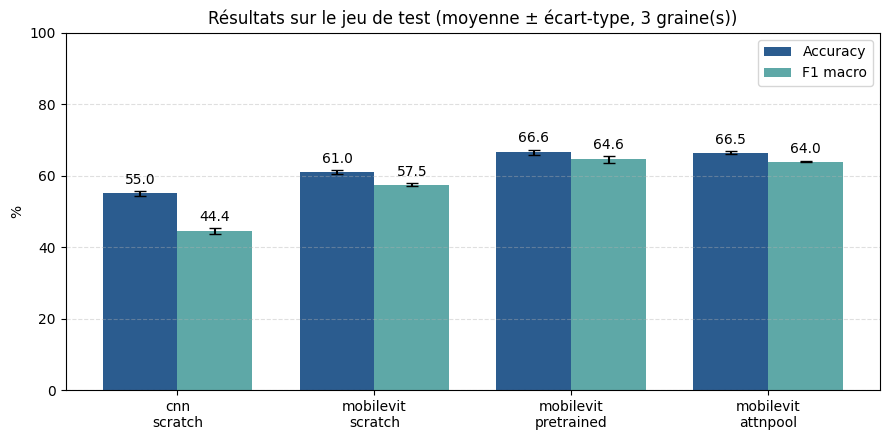

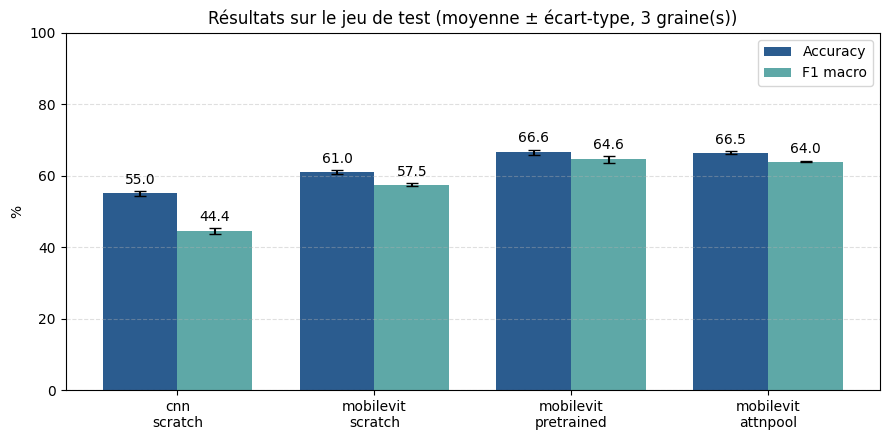

In [8]:
def load_df():
    rows = []
    for f in sorted(RESULTS.glob("*_seed*.json")):
        r = json.load(open(f))
        if r["epochs"] != EPOCHS or r["img_size"] != IMG_SIZE:
            continue
        rows.append(dict(model=r["name"], seed=r["seed"], acc=r["test_acc"] * 100,
                         f1=r["test_f1_macro"] * 100, val_acc=r["best_val_acc"] * 100,
                         best_epoch=r["best_epoch"], params_M=r["n_params"] / 1e6,
                         train_min=r["train_time_s"] / 60))
    return pd.DataFrame(rows)

df = load_df()
order = [m for m in EXPERIMENTS if m in set(df["model"])]
g = df.groupby("model")
mean_, std_ = g.mean(numeric_only=True).loc[order], g.std(numeric_only=True).fillna(0).loc[order]

summary = pd.DataFrame({
    "Accuracy test (%)": [f"{mean_.loc[m,'acc']:.2f} ± {std_.loc[m,'acc']:.2f}" for m in order],
    "F1 macro test (%)": [f"{mean_.loc[m,'f1']:.2f} ± {std_.loc[m,'f1']:.2f}" for m in order],
    "Accuracy val_sel (%)": [f"{mean_.loc[m,'val_acc']:.2f} ± {std_.loc[m,'val_acc']:.2f}" for m in order],
    "Paramètres (M)": [f"{mean_.loc[m,'params_M']:.2f}" for m in order],
    "Temps d'entraînement (min)": [f"{mean_.loc[m,'train_min']:.1f}" for m in order],
    "Nb de graines": [int(g.size()[m]) for m in order],
}, index=order)
summary.to_csv(RESULTS / "summary.csv")
display(summary)

# Graphique : accuracy et F1 macro avec barres d'erreur
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(order)); w = 0.38
b1 = ax.bar(x - w/2, mean_["acc"], w, yerr=std_["acc"], capsize=4, label="Accuracy", color="#2b5c8f")
b2 = ax.bar(x + w/2, mean_["f1"], w, yerr=std_["f1"], capsize=4, label="F1 macro", color="#5ea8a7")
ax.bar_label(b1, fmt="%.1f", padding=3); ax.bar_label(b2, fmt="%.1f", padding=3)
ax.set_xticks(x); ax.set_xticklabels([m.replace("_", "\n") for m in order])
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.legend(); ax.grid(axis="y", ls="--", alpha=.4)
ax.set_title(f"Résultats sur le jeu de test (moyenne ± écart-type, {len(SEEDS)} graine(s))")
plt.tight_layout(); plt.savefig(RESULTS / "comparison_bars.png", dpi=250, bbox_inches="tight"); plt.show()

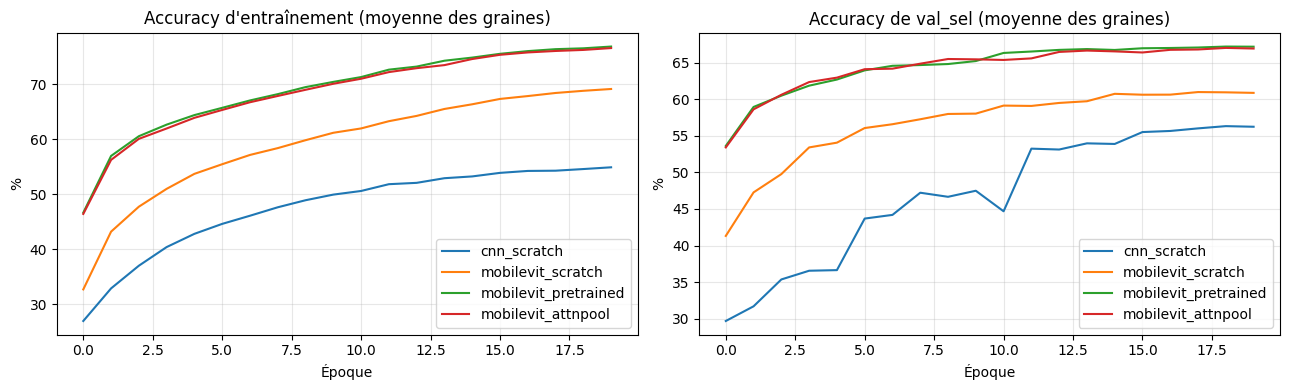

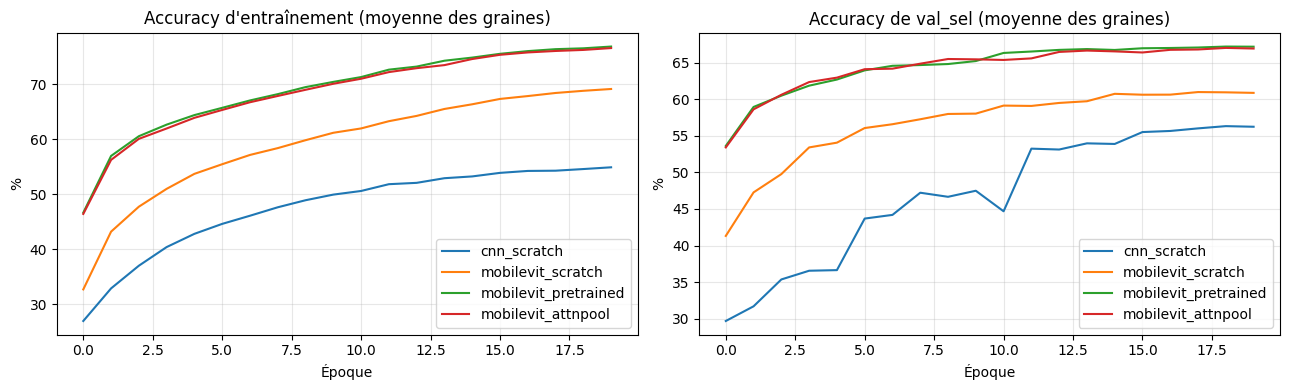

In [9]:
# Courbes d'apprentissage moyennes (surapprentissage ?)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in order:
    hs = [json.load(open(RESULTS / f"{name}_seed{s}.json"))["history"] for s in SEEDS
          if (RESULTS / f"{name}_seed{s}.json").exists()]
    ax[0].plot(np.mean([h["train_acc"] for h in hs], 0) * 100, label=name)
    ax[1].plot(np.mean([h["val_acc"] for h in hs], 0) * 100, label=name)
ax[0].set_title("Accuracy d'entraînement (moyenne des graines)")
ax[1].set_title("Accuracy de val_sel (moyenne des graines)")
for a in ax:
    a.set_xlabel("Époque"); a.set_ylabel("%"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(RESULTS / "learning_curves.png", dpi=250, bbox_inches="tight"); plt.show()

## 6. Efficacité : paramètres et latence

Contrairement au notebook précédent, la latence est mesurée **explicitement sur CPU**, avec **un batch de 1 image**, après 20 itérations d'échauffement, en prenant la **médiane** de 100 mesures (sans compter le chargement des données). La latence GPU est ajoutée si un GPU est disponible.

,params_M,cpu_ms,gpu_ms
modèle,,,
cnn_scratch,0.42,8.36,0.82
mobilevit_scratch,0.95,11.88,8.92
mobilevit_pretrained,0.95,12.72,11.54
mobilevit_attnpool,0.98,12.72,9.27


,params_M,cpu_ms,gpu_ms
modèle,,,
cnn_scratch,0.42,8.36,0.82
mobilevit_scratch,0.95,11.88,8.92
mobilevit_pretrained,0.95,12.72,11.54
mobilevit_attnpool,0.98,12.72,9.27


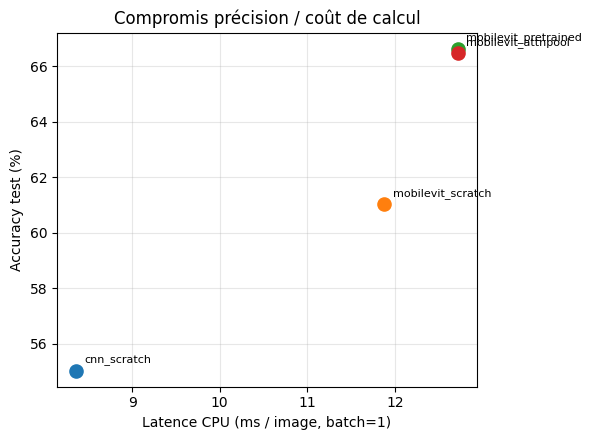

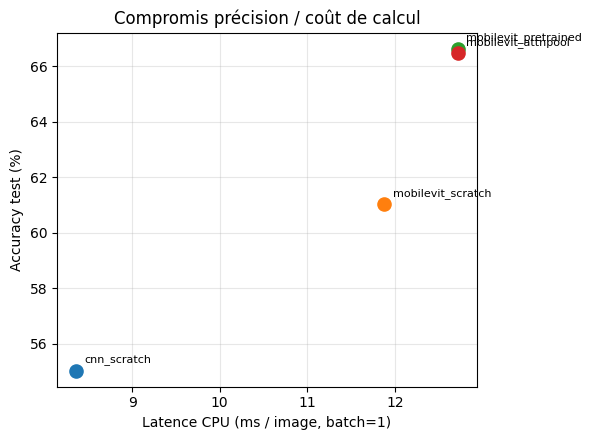

In [10]:
def latency_ms(model, dev, n=100, warm=20):
    model = model.to(dev).eval()
    x = torch.randn(1, 3, S, S, device=dev)
    ts = []
    with torch.no_grad():
        for _ in range(warm):
            model(x)
        if dev.type == "cuda": torch.cuda.synchronize()
        for _ in range(n):
            t = time.perf_counter()
            model(x)
            if dev.type == "cuda": torch.cuda.synchronize()
            ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts))

rows = []
for name in order:
    m = build_model(name, pretrained=False)     # les poids n'influent pas sur la latence
    row = dict(modèle=name, params_M=sum(p.numel() for p in m.parameters()) / 1e6,
               cpu_ms=latency_ms(m, torch.device("cpu")))
    if torch.cuda.is_available():
        row["gpu_ms"] = latency_ms(m, torch.device("cuda"))
    rows.append(row)
eff = pd.DataFrame(rows).set_index("modèle").round(2)
eff.to_csv(RESULTS / "efficiency.csv")
display(eff)

# Compromis précision / latence CPU
fig, ax = plt.subplots(figsize=(6, 4.5))
for name in order:
    ax.scatter(eff.loc[name, "cpu_ms"], mean_.loc[name, "acc"], s=90)
    ax.annotate(name, (eff.loc[name, "cpu_ms"], mean_.loc[name, "acc"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Latence CPU (ms / image, batch=1)"); ax.set_ylabel("Accuracy test (%)")
ax.set_title("Compromis précision / coût de calcul"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / "accuracy_vs_latency.png", dpi=250, bbox_inches="tight"); plt.show()

## 7. Analyse d'erreurs

### 7.1 F1 par classe et matrices de confusion

,cnn_scratch,mobilevit_scratch,mobilevit_pretrained,mobilevit_attnpool
angry,42.8,52.9,59.5,59.7
disgust,0.0,47.6,62.2,58.2
fear,21.8,39.9,49.8,50.4
happy,78.2,81.9,85.5,85.5
neutral,53.5,58.1,62.5,62.6
sad,43.9,47.6,54.7,53.6
surprise,70.9,74.3,77.6,77.8


,cnn_scratch,mobilevit_scratch,mobilevit_pretrained,mobilevit_attnpool
angry,42.8,52.9,59.5,59.7
disgust,0.0,47.6,62.2,58.2
fear,21.8,39.9,49.8,50.4
happy,78.2,81.9,85.5,85.5
neutral,53.5,58.1,62.5,62.6
sad,43.9,47.6,54.7,53.6
surprise,70.9,74.3,77.6,77.8


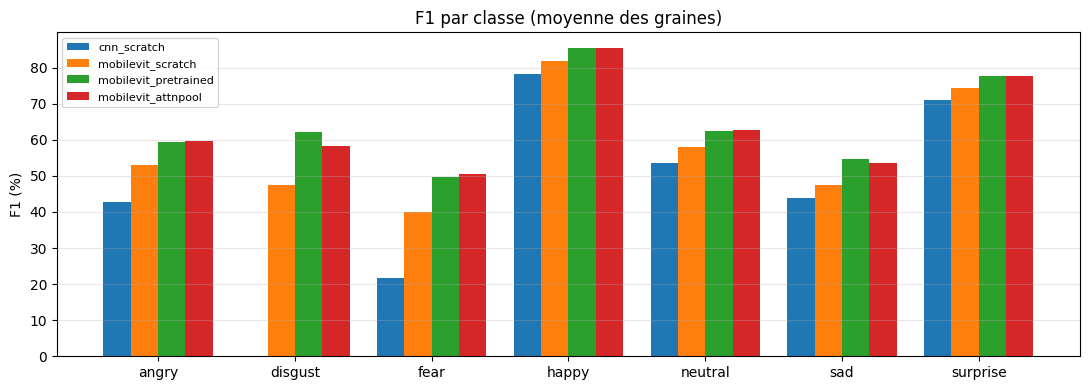

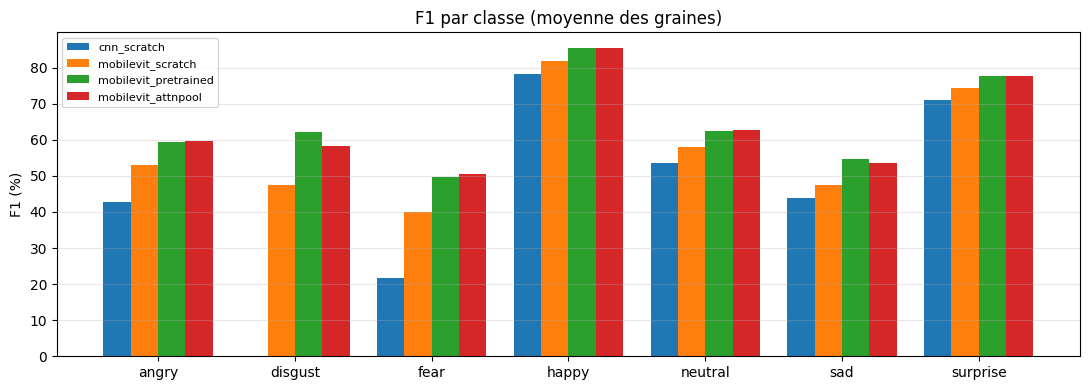

In [11]:
# F1 par classe (moyenne des graines)
pcf = {}
for name in order:
    arr = [json.load(open(RESULTS / f"{name}_seed{s}.json"))["per_class_f1"] for s in SEEDS
           if (RESULTS / f"{name}_seed{s}.json").exists()]
    pcf[name] = np.mean(arr, 0) * 100
pcf_df = pd.DataFrame(pcf, index=class_names).round(1)
display(pcf_df)

fig, ax = plt.subplots(figsize=(11, 4))
w = 0.8 / len(order); x = np.arange(NUM_CLASSES)
for i, name in enumerate(order):
    ax.bar(x + i * w - 0.4 + w / 2, pcf_df[name], w, label=name)
ax.set_xticks(x); ax.set_xticklabels(class_names); ax.set_ylabel("F1 (%)")
ax.set_title("F1 par classe (moyenne des graines)"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / "per_class_f1.png", dpi=250, bbox_inches="tight"); plt.show()

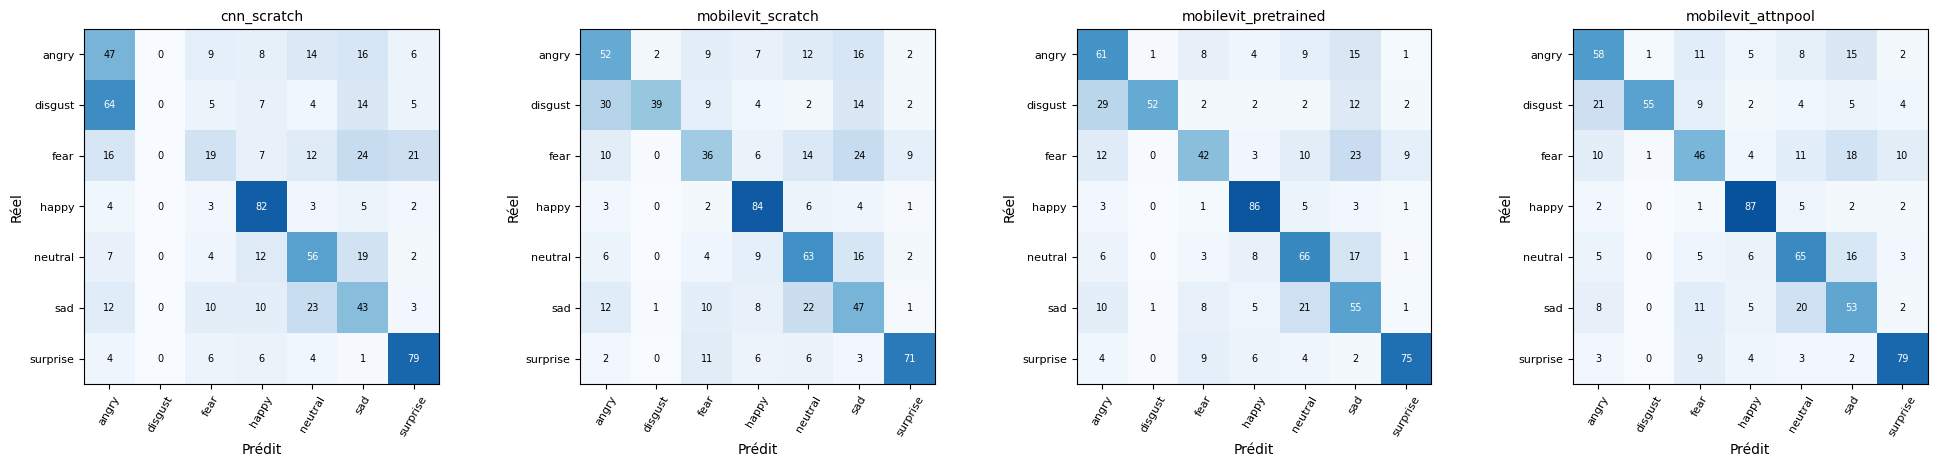

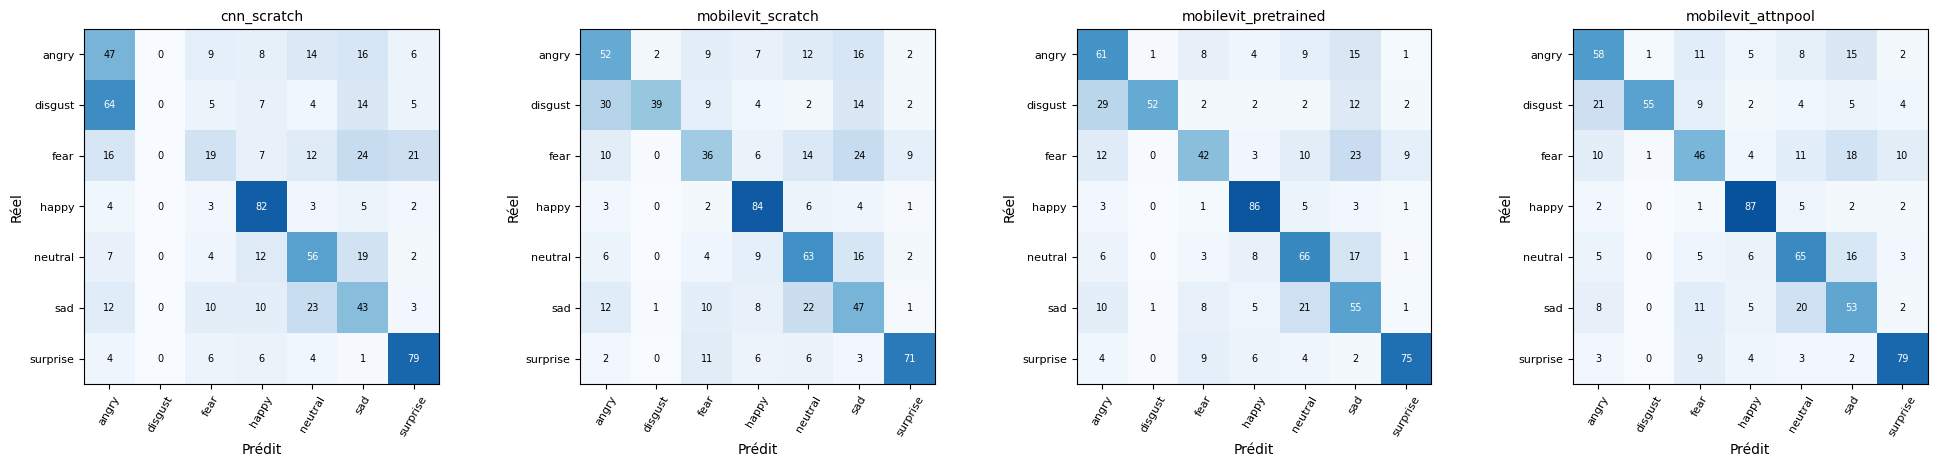

Meilleur modèle (accuracy test moyenne) : mobilevit_pretrained
Principales confusions (réel -> prédit, % de la classe réelle) :
  disgust   -> angry     : 28.6%
  fear      -> sad       : 22.9%
  sad       -> neutral   : 21.0%
  neutral   -> sad       : 17.0%
  angry     -> sad       : 15.0%
Meilleur modèle (accuracy test moyenne) : mobilevit_pretrained
Principales confusions (réel -> prédit, % de la classe réelle) :
  disgust   -> angry     : 28.6%
  fear      -> sad       : 22.9%
  sad       -> neutral   : 21.0%
  neutral   -> sad       : 17.0%
  angry     -> sad       : 15.0%


In [12]:
# Matrices de confusion normalisées (graine SEEDS[0]) pour les 4 modèles
fig, axes = plt.subplots(1, len(order), figsize=(5 * len(order), 4.6))
axes = np.atleast_1d(axes)
cms = {}
for ax, name in zip(axes, order):
    r = json.load(open(RESULTS / f"{name}_seed{SEEDS[0]}.json"))
    cm = confusion_matrix(r["test_targets"], r["test_preds"], labels=range(NUM_CLASSES), normalize="true")
    cms[name] = cm
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(class_names, rotation=60, fontsize=8); ax.set_yticklabels(class_names, fontsize=8)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, f"{cm[i, j]*100:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > .5 else "black")
    ax.set_title(name, fontsize=10); ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
plt.tight_layout(); plt.savefig(RESULTS / "confusion_matrices.png", dpi=250, bbox_inches="tight"); plt.show()

# Principales confusions du meilleur modèle
best_name = mean_["acc"].idxmax()
cm = cms[best_name].copy(); np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]
print(f"Meilleur modèle (accuracy test moyenne) : {best_name}")
print("Principales confusions (réel -> prédit, % de la classe réelle) :")
for i, j in top:
    print(f"  {class_names[i]:9s} -> {class_names[j]:9s} : {cm[i, j]*100:.1f}%")

### 7.2 Exemples mal classés

On affiche, pour le meilleur modèle (graine `SEEDS[0]`), les erreurs où le modèle était **le plus sûr de lui**. Beaucoup relèvent de l'ambiguïté de l'étiquette (FER-2013 est bruité).

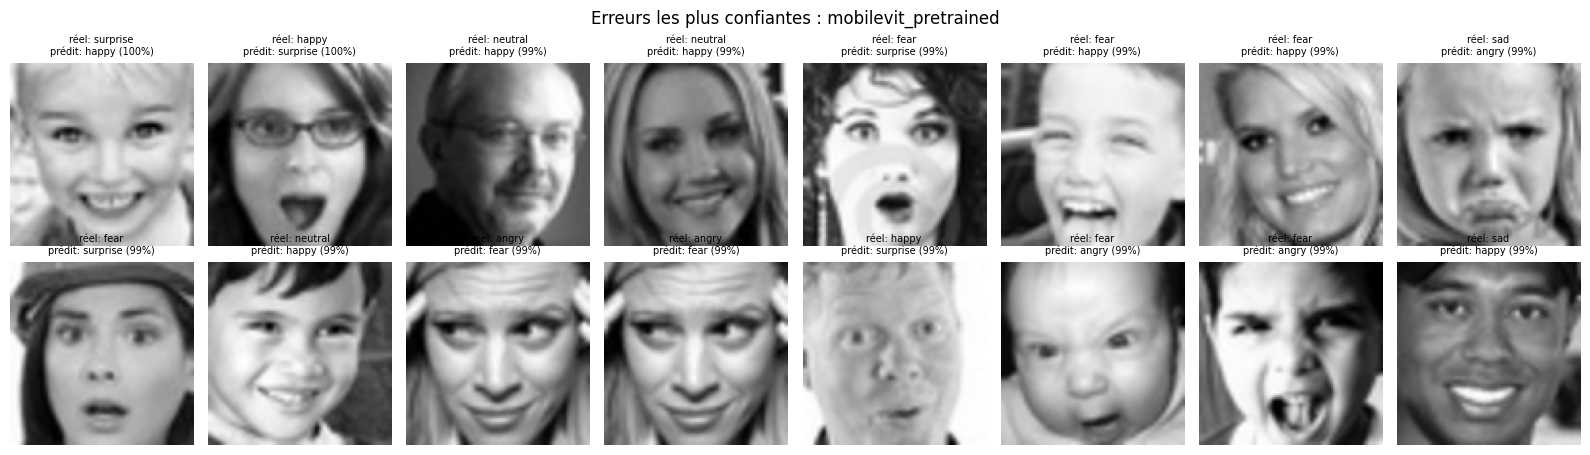

In [16]:
def denorm(x):
    m = torch.tensor(mean).view(3, 1, 1); s = torch.tensor(std).view(3, 1, 1)
    return (x.cpu() * s + m).clamp(0, 1)[0].numpy()

def load_trained(name, seed):
    m = build_model(name, pretrained=False)
    m.load_state_dict(torch.load(RESULTS / "ckpt" / f"{name}_seed{seed}.pth", map_location="cpu"))
    return m.to(device).eval()

best_model = load_trained(best_name, SEEDS[0])
test_loader = make_loader(test_ds, False)
all_p, all_t, all_conf = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        pr = F.softmax(best_model(x.to(device)).float(), 1).cpu()
        c, p = pr.max(1)
        all_p.append(p); all_t.append(y); all_conf.append(c)
all_p, all_t, all_conf = torch.cat(all_p).numpy(), torch.cat(all_t).numpy(), torch.cat(all_conf).numpy()
wrong = np.where(all_p != all_t)[0]
worst = wrong[np.argsort(-all_conf[wrong])[:16]]

fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, k in zip(axes.ravel(), worst):
    img, _ = test_ds[int(k)]
    ax.imshow(denorm(img), cmap="gray"); ax.axis("off")
    ax.set_title(f"réel: {class_names[all_t[k]]}\nprédit: {class_names[all_p[k]]} ({all_conf[k]*100:.0f}%)", fontsize=7)
plt.suptitle(f"Erreurs les plus confiantes : {best_name}")
plt.tight_layout(); plt.savefig(RESULTS / "worst_errors.png", dpi=250, bbox_inches="tight"); plt.show()

### 7.3 Interprétabilité : Grad-CAM (CNN) et cartes d'attention (pooling attentionnel)

- **Grad-CAM** sur la dernière couche convolutive du CNN : où le réseau regarde-t-il pour décider ?
- **Cartes d'attention** de `AttnPoolHead` : les poids appris par le pooling attentionnel. La carte de MobileViT est de petite taille (par ex. 3×3 pour une entrée de 96 px) : elle est donc grossière.

On prend un exemple **par classe** dans le jeu de test.

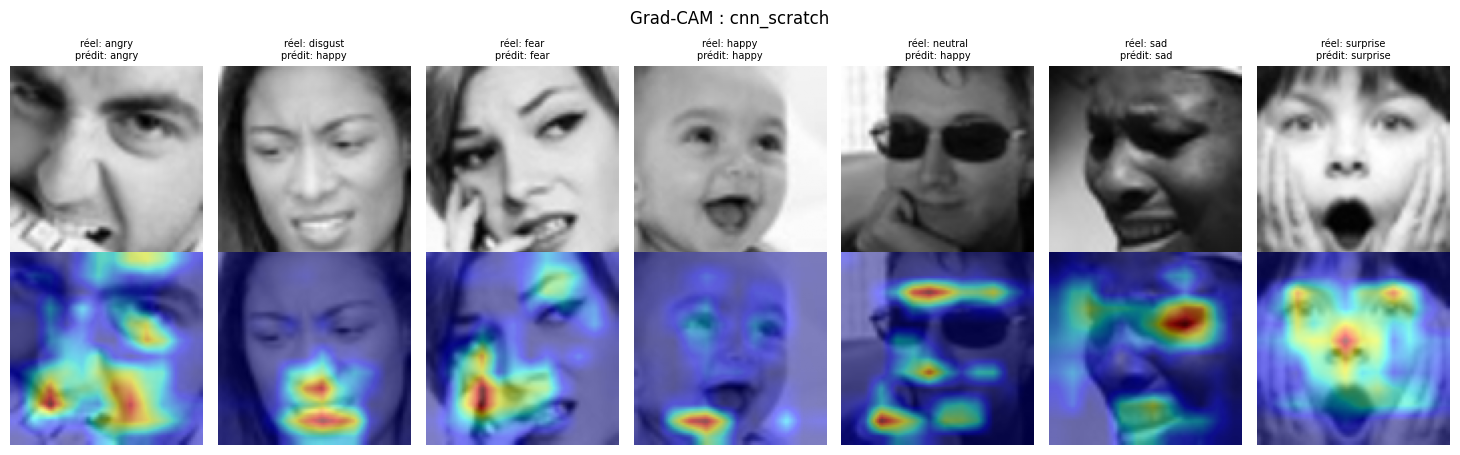

In [18]:
def gradcam(model, x, layer):
    acts, grads = {}, {}
    def fwd_hook(m, i, o):
        acts["a"] = o
        o.register_hook(lambda g: grads.__setitem__("g", g))
    h = layer.register_forward_hook(fwd_hook)
    model.zero_grad()
    out = model(x)
    cls = out.argmax(1)
    out.gather(1, cls[:, None]).sum().backward()
    h.remove()
    w = grads["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam - cam.amin((2, 3), keepdim=True)
    cam = cam / (cam.amax((2, 3), keepdim=True) + 1e-8)
    return cam[:, 0].detach().cpu().numpy(), cls.detach().cpu().numpy()

def show_maps(imgs, maps, titles, fname, suptitle):
    n = len(imgs)
    fig, axes = plt.subplots(2, n, figsize=(2.1 * n, 4.6))
    for i in range(n):
        axes[0, i].imshow(imgs[i], cmap="gray"); axes[0, i].axis("off"); axes[0, i].set_title(titles[i], fontsize=7)
        axes[1, i].imshow(imgs[i], cmap="gray"); axes[1, i].imshow(maps[i], cmap="jet", alpha=.5); axes[1, i].axis("off")
    plt.suptitle(suptitle); plt.tight_layout()
    plt.savefig(RESULTS / fname, dpi=250, bbox_inches="tight"); plt.show()

# Un exemple par classe (premier rencontré dans le test)
test_targets_arr = targets_full[idx_test]
sample_idx = [int(np.where(test_targets_arr == c)[0][0]) for c in range(NUM_CLASSES)]
xs = torch.stack([test_ds[i][0] for i in sample_idx]).to(device)
imgs = [denorm(xs[i]) for i in range(len(sample_idx))]      # <-- xs[i] et non xs[i:i+1]

# Grad-CAM sur le CNN
cnn = load_trained("cnn_scratch", SEEDS[0])
cams, cls = gradcam(cnn, xs, cnn.features[14])     # sortie du dernier bloc (ReLU)
titles = [f"réel: {class_names[test_targets_arr[i]]}\nprédit: {class_names[c]}" for i, c in zip(sample_idx, cls)]
show_maps(imgs, cams, titles, "gradcam_cnn.png", "Grad-CAM : cnn_scratch")

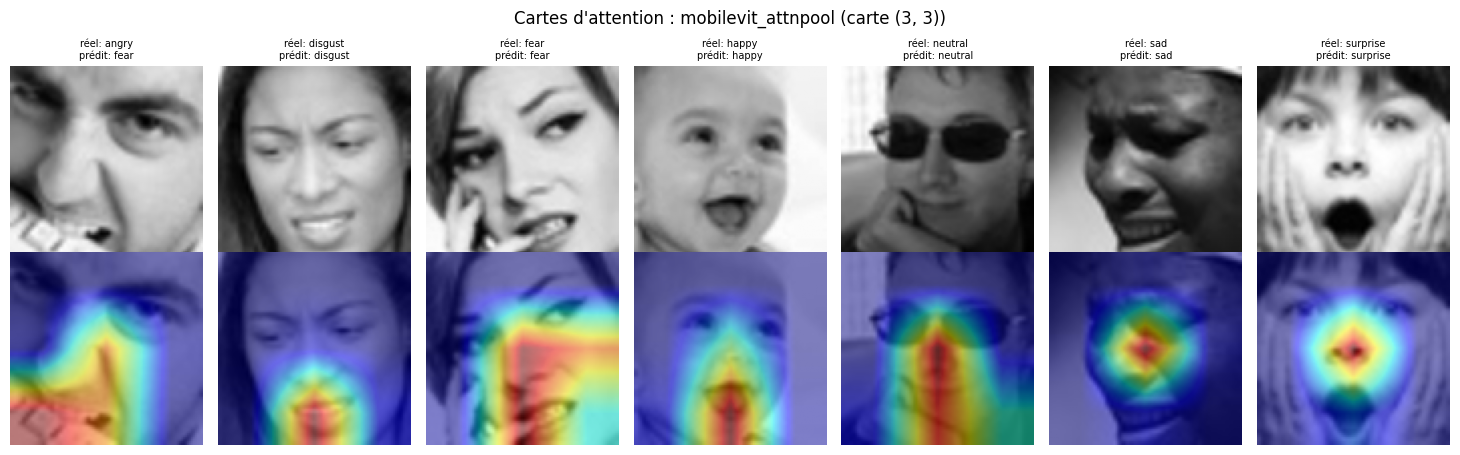

In [19]:
# Cartes d'attention du pooling attentionnel
if "mobilevit_attnpool" in order:
    att_model = load_trained("mobilevit_attnpool", SEEDS[0])
    with torch.no_grad():
        out, attn = att_model(xs, return_attn=True)
    pred = out.argmax(1).cpu().numpy()
    attn_up = F.interpolate(attn[:, None], size=(S, S), mode="bilinear", align_corners=False)[:, 0].cpu().numpy()
    attn_up = (attn_up - attn_up.min((1, 2), keepdims=True)) / (np.ptp(attn_up, axis=(1, 2), keepdims=True) + 1e-8)
    titles = [f"réel: {class_names[test_targets_arr[i]]}\nprédit: {class_names[p]}" for i, p in zip(sample_idx, pred)]
    show_maps(imgs, attn_up, titles, "attention_maps.png",
              f"Cartes d'attention : mobilevit_attnpool (carte {tuple(attn.shape[1:])})")

## 8. Export des résultats

Archive `results.zip` (figures, tableaux CSV, JSON de chaque exécution, checkpoints).

In [20]:
archive = shutil.make_archive(str(RESULTS), "zip", RESULTS)
print("Archive créée :", os.path.abspath(archive))

if Path("/kaggle/working").exists():
    print("Sur Kaggle : récupérez results.zip dans l'onglet Output (clic sur les ... > Download).")
else:
    try:
        from google.colab import files
        files.download(archive)
    except ImportError:
        pass

Archive créée : /content/results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>